## ANN & Deep Learning
 Overview: Heart Disease Classification using Neural Network and AdaBoost

**Goal:** Build and compare two binary classifiers — a custom neural network and an AdaBoost ensemble — to predict presence/absence of heart disease using the UCI Cleveland Heart Disease dataset (303 patients, 13 features).

**What you'll do:**

1. **Setup** — Mount Google Drive and load the dataset (13 features + target; missing values expected in `ca` and `thal`).
2. **Explore the data** — Check shape, columns, dtypes, and summary statistics; understand what each feature and the target represent.
3. **Check class balance** — Count and visualize the target distribution, and determine whether the dataset is balanced or imbalanced.
4. **Assess data quality** — Identify missing values, duplicates, and unique value counts; decide how to handle missing data.
5. **Visualize** — Plot the target distribution, a couple of feature relationships, and a correlation heatmap.
6. **Preprocess** — Split features/target, separate numerical vs. categorical columns, impute missing values, encode categoricals, scale numerics, and split into train/test sets — all without leaking test data into training.
7. **Design a neural network** — Choose your own 4–5 layer architecture (neurons, activations) and record it in a table.
8. **Calculate parameters by hand** — Manually compute trainable parameters per layer using the standard formula, before verifying against Keras.
9. **Build and train the network** — Implement your design in Keras, choose a loss function and optimizer (with justification), compile, and train, tracking a validation split.
10. **Diagnose training** — Plot training vs. validation loss and comment on overfitting.
11. **Evaluate the network** — Compute accuracy, precision, recall, and F1-score on the test set.
12. **Build AdaBoost** — Train a second model (`AdaBoostClassifier`) and compute the same four metrics.
13. **Compare models** — Fill in a comparison table and discuss differences, likely causes, overfitting signs, and preprocessing impact.
14. **Wrap up** — Write a short final interpretation covering balance, preprocessing, your architecture, both models' results, the comparison, and possible improvements.

# Heart Disease Classification using Neural Network and AdaBoost

**Dataset:** UCI Heart Disease dataset (Cleveland / processed version)
**Source:** https://archive.ics.uci.edu/dataset/45/heart+disease

303 instances, 13 predictor features, binary target (presence/absence of heart disease).
Missing values are documented for the `ca` and `thal` columns.

> Before the lab: download the processed Cleveland dataset (`processed.cleveland.data` or the CSV version) and upload it to your Google Drive.



## Cell 1 — Mount Google Drive

In [ ]:
# Mount Google Drive to access the dataset
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:          # running locally (not in Colab)
    IN_COLAB = False
print("Running in Colab:", IN_COLAB)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Running in Colab: True


In [ ]:
# Set the path to your dataset in Google Drive (edit the folder name below)
import os, gdown
DATA_PATH = "/content/heart_disease.csv"
gdown.download(id="1lU-_vF6n3Vf9slwjKYaCY02B56ahV-BX", output=DATA_PATH, quiet=False)

Downloading...
From: https://drive.google.com/uc?id=1lU-_vF6n3Vf9slwjKYaCY02B56ahV-BX
To: /content/heart_disease.csv
100%|██████████| 129k/129k [00:00<00:00, 34.5MB/s]


'/content/heart_disease.csv'

## Cell 2 — Import Libraries

In [ ]:
# Core data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing and model selection
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Ensemble model
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

# Evaluation metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Neural network
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Reproducibility
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

sns.set_theme(style="whitegrid")

## Cell 3 — Load Dataset

In [ ]:
# Load the UCI Heart Disease dataset from DATA_PATH
# The raw UCI file has no header row and uses '?' for missing values -- handle both.
column_names = [
    "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
    "thalach", "exang", "oldpeak", "slope", "ca", "thal", "target"
]

import io, zipfile
zf = zipfile.ZipFile(DATA_PATH)
member = next(n for n in zf.namelist() if n.endswith("processed.cleveland.data"))
df = pd.read_csv(io.BytesIO(zf.read(member)), header=None, names=column_names,
                 na_values="?", skipinitialspace=True)

# Safety net: if a CSV version *with* a header was used, the first row is text -> drop it
if not pd.api.types.is_numeric_dtype(df["age"]):
    df = df.iloc[1:].apply(pd.to_numeric, errors="coerce").reset_index(drop=True)

# Original target is 0 (no disease) to 4 (severity). Convert to binary:
# 0 = absence, 1 = presence (values 1-4), as the UCI documentation recommends.
df["num"] = df["target"]                   # keep original severity for reference
df["target"] = (df["target"] > 0).astype(int)
df = df.drop(columns=["num"])

print("Loaded shape:", df.shape)
df.head()

Loaded shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## Cell 4 — Understand the Dataset

Explore the dataset and answer, in a markdown cell or comments below:
- How many samples and features are there?
- What are the column names and data types?
- What do the first 5 rows look like?
- What are the descriptive statistics (`describe()`)?
- What is the target variable and what values does it take?

In [ ]:
# Inspect shape, columns, dtypes, head(), and describe()
print("Shape (rows, columns):", df.shape)
print("Number of samples :", df.shape[0])
print("Number of features:", df.shape[1] - 1, "(+1 target)")
print("\nColumns:", list(df.columns))
print("\nData types:")
print(df.dtypes)

Shape (rows, columns): (303, 14)
Number of samples : 303
Number of features: 13 (+1 target)

Columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Data types:
age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
target        int64
dtype: object


In [ ]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [ ]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.16,0.96,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.99,0.99,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2


In [ ]:
print("Target values:", sorted(df["target"].unique()))  # 0 = no disease, 1 = disease

Target values: [np.int64(0), np.int64(1)]


**Answers — Cell 4**

- **Samples / features:** 303 patients, 13 predictor features + 1 target column (14 columns).
- **Columns:** `age, sex, cp, trestbps, chol, fbs, restecg, thalach, exang, oldpeak, slope, ca, thal, target`.
- **Data types:** all numeric — 11 integer columns; `oldpeak`, `ca` and `thal` are float (`ca`/`thal` become float because they contain NaN). Several integer columns are really **categorical codes** (`sex, cp, fbs, restecg, exang, slope, thal`).
- **First 5 rows:** shown above (e.g. patient 1: 63-year-old male, cp = 1, chol = 233, no disease).
- **Descriptive statistics:** mean age 54.4 years (29–77), 68% male, mean cholesterol 246.7 mg/dl (max 564 — an outlier), mean max heart rate 149.6 bpm. `ca` has 299 and `thal` 301 non-null values, confirming missing data.
- **Target:** originally `num` with values 0–4 (0 = no disease, 1–4 = increasing severity). Following the UCI documentation it was converted to **binary**: **0 = absence**, **1 = presence** of heart disease.

| Feature | Meaning |
|---|---|
| age | Age in years |
| sex | 1 = male, 0 = female |
| cp | Chest pain type (1 typical angina, 2 atypical, 3 non-anginal, 4 asymptomatic) |
| trestbps | Resting blood pressure (mm Hg) |
| chol | Serum cholesterol (mg/dl) |
| fbs | Fasting blood sugar > 120 mg/dl (1 = true) |
| restecg | Resting ECG result (0, 1, 2) |
| thalach | Maximum heart rate achieved |
| exang | Exercise-induced angina (1 = yes) |
| oldpeak | ST depression induced by exercise |
| slope | Slope of peak exercise ST segment (1 up, 2 flat, 3 down) |
| ca | Number of major vessels coloured by fluoroscopy (0–3) |
| thal | 3 = normal, 6 = fixed defect, 7 = reversible defect |

## Cell 5 — Check Balanced vs. Imbalanced Data

Investigate the target variable:
- Count of each class
- Percentage of each class
- Plot the target distribution
- State whether the dataset is balanced or imbalanced, and briefly explain why.

                Count  Percentage (%)
0 - No disease    164           54.13
1 - Disease       139           45.87


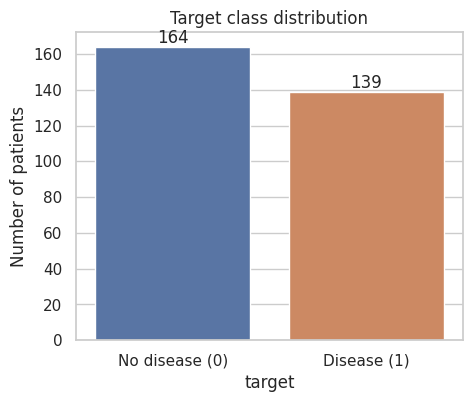

Minority/majority ratio: 0.85


In [ ]:
# Count target classes, compute percentages, and plot the distribution
counts = df["target"].value_counts().sort_index()
percent = df["target"].value_counts(normalize=True).sort_index() * 100

balance = pd.DataFrame({"Count": counts, "Percentage (%)": percent.round(2)})
balance.index = ["0 - No disease", "1 - Disease"]
print(balance)

plt.figure(figsize=(5, 4))
ax = sns.countplot(x="target", data=df, hue="target", palette=["#4C72B0", "#DD8452"], legend=False)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
ax.set_xticks([0, 1])
ax.set_xticklabels(["No disease (0)", "Disease (1)"])
plt.title("Target class distribution")
plt.ylabel("Number of patients")
plt.show()

ratio = counts.min() / counts.max()
print(f"Minority/majority ratio: {ratio:.2f}")

**Answer — Cell 5:** Class 0 (no disease) = **164 (54.13%)**, class 1 (disease) = **139 (45.87%)**. The minority/majority ratio is 0.85, so the dataset is **(approximately) balanced** — the split is close to 50/50 and neither class dominates. No resampling or class weighting is needed; accuracy is a meaningful metric here, although we still report precision, recall and F1. A stratified train/test split is used to keep this ratio in both sets.

## Cell 6 — Missing Values and Data Quality

Check the dataset for:
- Missing / null values (remember '?' may need to be converted to NaN first)
- Duplicate rows
- Data types of each column
- Unique values per column

Identify which columns have missing values and decide how you will handle them (this decision is used later in preprocessing).

In [ ]:
# Check for missing values, duplicates, dtypes, and unique values per column
missing = df.isnull().sum()
quality = pd.DataFrame({
    "dtype": df.dtypes,
    "missing": missing,
    "missing_%": (missing / len(df) * 100).round(2),
    "unique_values": df.nunique()
})
print(quality)

print("\nColumns with missing values:", list(missing[missing > 0].index))
print("Total missing cells:", int(missing.sum()))
print("Duplicate rows:", df.duplicated().sum())

print("\nUnique values of categorical-looking columns:")
for col in ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]:
    print(f"  {col:8s}: {sorted(df[col].dropna().unique())}")

            dtype  missing  missing_%  unique_values
age       float64        0       0.00             41
sex       float64        0       0.00              2
cp        float64        0       0.00              4
trestbps  float64        0       0.00             50
chol      float64        0       0.00            152
fbs       float64        0       0.00              2
restecg   float64        0       0.00              3
thalach   float64        0       0.00             91
exang     float64        0       0.00              2
oldpeak   float64        0       0.00             40
slope     float64        0       0.00              3
ca        float64        4       1.32              4
thal      float64        2       0.66              3
target      int64        0       0.00              2

Columns with missing values: ['ca', 'thal']
Total missing cells: 6
Duplicate rows: 0

Unique values of categorical-looking columns:
  sex     : [np.float64(0.0), np.float64(1.0)]
  cp      : [np.float64(1

**Answer — Cell 6:**

- **Missing values:** only 6 cells in total — `ca` has **4** (1.32%) and `thal` has **2** (0.66%). All other columns are complete.
- **Duplicates:** **0** duplicate rows.
- **Data types / unique values:** binary columns (`sex, fbs, exang`) have 2 values; `cp` 4; `restecg, slope, thal` 3; `ca` 4 (0–3); continuous columns (`age, trestbps, chol, thalach, oldpeak`) have many unique values.

**Decision:** because so few rows are affected (6 values, < 2%), the rows are **kept** and the values are **imputed** instead of dropped (dropping would lose ~2% of an already small dataset):
- `ca` (ordinal count) → **median** imputation
- `thal` (categorical) → **most-frequent (mode)** imputation

The imputers are part of the preprocessing pipeline and are fitted **only on the training data** (Cell 8) so no information from the test set leaks into training.

## Cell 7 — Data Visualization

Create and briefly interpret:
- Target distribution plot
- At least 2 additional visualizations of your choice (e.g. age distribution, feature vs. target)
- Correlation heatmap of numerical features

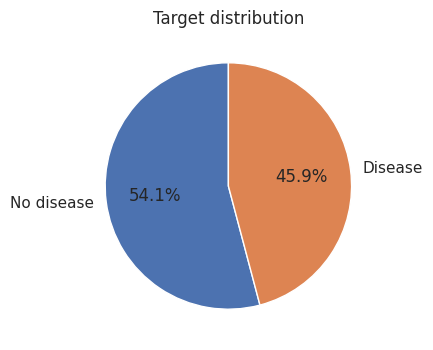

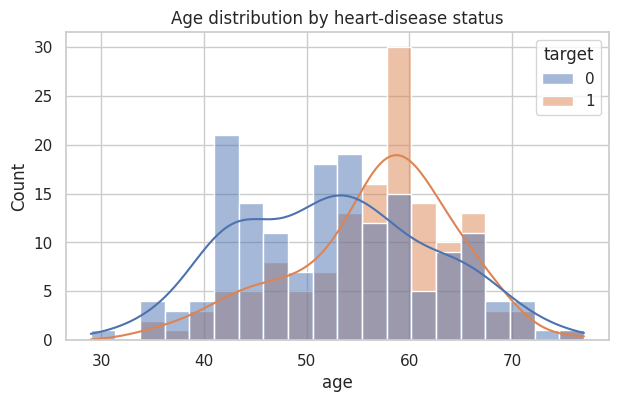

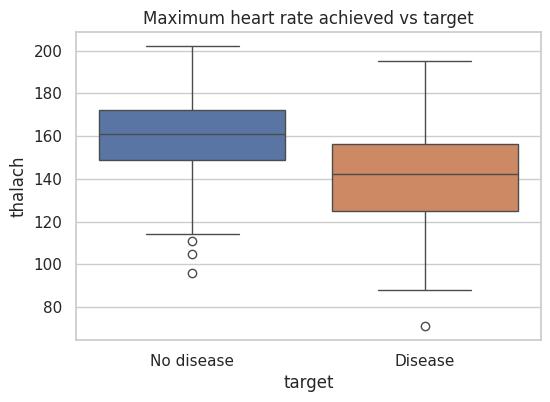

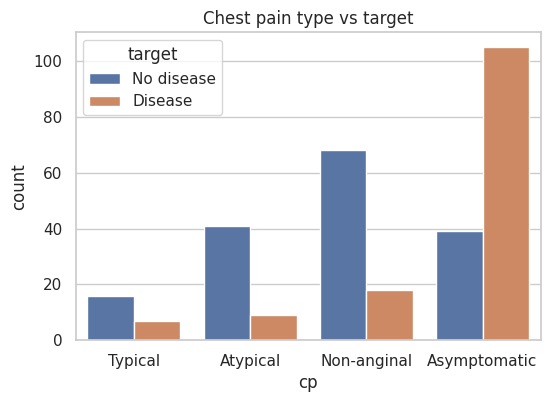

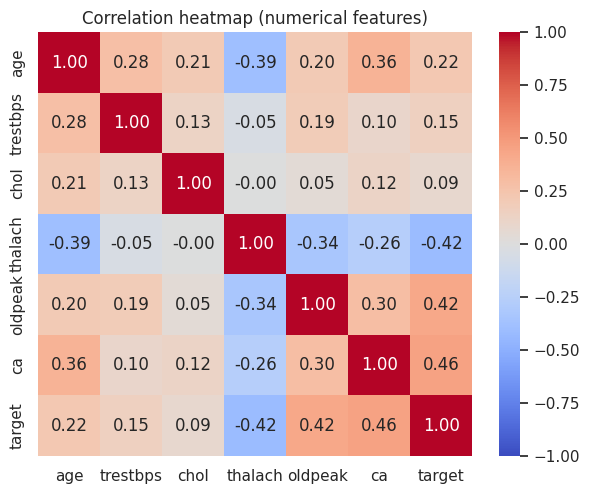

thalach    -0.417
chol        0.085
trestbps    0.151
age         0.223
oldpeak     0.425
ca          0.460
Name: target, dtype: float64


In [ ]:
# 1) Target distribution (pie chart, complements the bar chart in Cell 5)
plt.figure(figsize=(4, 4))
df["target"].value_counts().sort_index().plot.pie(
    labels=["No disease", "Disease"], autopct="%1.1f%%", colors=["#4C72B0", "#DD8452"], startangle=90)
plt.title("Target distribution")
plt.ylabel("")
plt.show()

# 2) Age distribution by target
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="age", hue="target", kde=True, bins=20, palette=["#4C72B0", "#DD8452"])
plt.title("Age distribution by heart-disease status")
plt.show()

# 3) Max heart rate (thalach) vs target
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x="target", y="thalach", hue="target", palette=["#4C72B0", "#DD8452"], legend=False)
plt.xticks([0, 1], ["No disease", "Disease"])
plt.title("Maximum heart rate achieved vs target")
plt.show()

# 4) Chest pain type vs target
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="cp", hue="target", palette=["#4C72B0", "#DD8452"])
plt.xticks([0, 1, 2, 3], ["Typical", "Atypical", "Non-anginal", "Asymptomatic"])
plt.legend(title="target", labels=["No disease", "Disease"])
plt.title("Chest pain type vs target")
plt.show()

# 5) Correlation heatmap of numerical features (+ target)
num_cols = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca", "target"]
plt.figure(figsize=(7, 5.5))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation heatmap (numerical features)")
plt.show()

print(df[num_cols].corr()["target"].drop("target").sort_values().round(3))

**Interpretation — Cell 7:**

- **Target distribution:** 54% no disease vs 46% disease — roughly balanced (confirms Cell 5).
- **Age:** patients with heart disease are concentrated in the 55–65 range, while the no-disease group is spread more widely and includes more younger patients — risk rises with age.
- **Max heart rate (`thalach`):** patients with disease reach a clearly **lower** maximum heart rate (median ≈ 142 vs ≈ 161 bpm); this is one of the strongest single predictors.
- **Chest pain type:** most disease cases have **asymptomatic** chest pain (cp = 4), while typical/atypical/non-anginal pain is more common in healthy patients — a counter-intuitive but well-known pattern in this dataset.
- **Correlation heatmap:** the features most correlated with the target are `ca` (+0.46), `oldpeak` (+0.43) and `thalach` (−0.42); `age` is moderate (+0.22) while `chol` (+0.09) and `trestbps` (+0.15) are weak. Correlations among the predictors themselves are moderate (largest ≈ |0.4|, e.g. `age`–`thalach`), so there is no serious multicollinearity.

## Cell 8 — Preprocessing

- Separate features `X` and target `y`
- Identify numerical and categorical features
- Handle missing values (based on your Cell 6 decision)
- Encode categorical variables
- Scale numerical features where appropriate
- Split into training and testing sets

Build a preprocessing pipeline (e.g. `ColumnTransformer`) and fit it only on the training data to avoid data leakage.

In [ ]:
# Define X and y
X = df.drop(columns=["target"])
y = df["target"]

# Identify numerical and categorical features
numerical_features = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca"]
categorical_features = ["sex", "cp", "fbs", "restecg", "exang", "slope", "thal"]

# Split into train/test sets FIRST (stratified, keeps class ratio)
X_train_df, X_test_df, y_train_s, y_test_s = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Numerical: median imputation (ca has missing values) + standard scaling
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical: most-frequent imputation (thal has missing values) + one-hot encoding
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", drop="if_binary", sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

# Fit ONLY on training data -> no test-set leakage; then transform both
X_train_np = preprocessor.fit_transform(X_train_df)
X_test_np = preprocessor.transform(X_test_df)

feature_names = preprocessor.get_feature_names_out()
print("Train shape:", X_train_np.shape, " Test shape:", X_test_np.shape)
print("Features after encoding:", len(feature_names))
print(list(feature_names))

# Hold out 15% of the TRAINING set as a validation set to monitor overfitting
X_tr_np, X_val_np, y_tr_np, y_val_np = train_test_split(
    X_train_np, y_train_s.values,
    test_size=0.15, random_state=42, stratify=y_train_s
)

# Convert to PyTorch tensors (float targets for BCEWithLogitsLoss, shape [N, 1])
X_train = torch.tensor(X_tr_np, dtype=torch.float32)
X_val = torch.tensor(X_val_np, dtype=torch.float32)
X_test = torch.tensor(X_test_np, dtype=torch.float32)

y_train = torch.tensor(y_tr_np, dtype=torch.float32).unsqueeze(1)
y_val = torch.tensor(y_val_np, dtype=torch.float32).unsqueeze(1)
y_test = torch.tensor(y_test_s.values, dtype=torch.float32).unsqueeze(1)

print("NN train / val / test sizes:", len(X_train), len(X_val), len(X_test))

Train shape: (242, 22)  Test shape: (61, 22)
Features after encoding: 22
['num__age', 'num__trestbps', 'num__chol', 'num__thalach', 'num__oldpeak', 'num__ca', 'cat__sex_1.0', 'cat__cp_1.0', 'cat__cp_2.0', 'cat__cp_3.0', 'cat__cp_4.0', 'cat__fbs_1.0', 'cat__restecg_0.0', 'cat__restecg_1.0', 'cat__restecg_2.0', 'cat__exang_1.0', 'cat__slope_1.0', 'cat__slope_2.0', 'cat__slope_3.0', 'cat__thal_3.0', 'cat__thal_6.0', 'cat__thal_7.0']
NN train / val / test sizes: 205 37 61


In [ ]:
# Create TensorDatasets
train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)
test_dataset = TensorDataset(X_test, y_test)

# Create DataLoaders
g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, generator=g)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

## Cell 9 — Design Your Own Neural Network

Design: **5 layers total** — input + 3 hidden + output (a funnel 32 → 16 → 8 that halves the width at each step).

After preprocessing, the 13 original features become **22 inputs** (6 scaled numerical + 16 one-hot columns: `sex` 1, `cp` 4, `fbs` 1, `restecg` 3, `exang` 1, `slope` 3, `thal` 3).

| Layer    | Neurons | Activation |
|----------|--------:|------------|
| Input    | 22 | None (features passed through) |
| Hidden 1 | 32 | ReLU (+ Dropout 0.3) |
| Hidden 2 | 16 | ReLU (+ Dropout 0.3) |
| Hidden 3 | 8  | ReLU |
| Output   | 1  | Sigmoid (applied inside `BCEWithLogitsLoss` / at prediction) |

**Design choices:**
- **ReLU** in hidden layers: simple, fast, and avoids vanishing gradients.
- **Sigmoid output with 1 neuron:** binary task, gives the probability of heart disease.
- **Small, narrowing network:** only ~240 training samples, so a small model limits overfitting; **Dropout (0.3)** adds extra regularization (dropout layers have no trainable parameters).

## Cell 10 — Manually Calculate Parameters

`Parameters = (Input units × Output units) + Output units`

| Layer    | Input Units | Output Units | Calculation | Parameters |
|----------|------------:|-------------:|-------------|-----------:|
| Hidden 1 | 22 | 32 | (22 × 32) + 32 = 704 + 32 | 736 |
| Hidden 2 | 32 | 16 | (32 × 16) + 16 = 512 + 16 | 528 |
| Hidden 3 | 16 | 8  | (16 × 8) + 8 = 128 + 8 | 136 |
| Output   | 8  | 1  | (8 × 1) + 1 = 8 + 1 | 9 |
| **Total**|    |    | 736 + 528 + 136 + 9 | **1,409** |

The PyTorch parameter count printed in Cell 11 (our equivalent of Keras `model.summary()`) is also **1,409**, so the manual calculation is confirmed. The input layer and the Dropout/ReLU layers have no trainable parameters.

## Cell 11 — Implement Neural Network in PyTorch


In [ ]:
# Implement the architecture designed in Cell 9
import torch
import torch.nn as nn


class MyModel(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super().__init__()

        self.model = nn.Sequential(
            # Input -> Hidden 1
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.3),

            # Hidden 2
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(0.3),

            # Hidden 3
            nn.Linear(hidden_dim // 2, hidden_dim // 4),
            nn.ReLU(),

            # Output layer (single logit; sigmoid applied in the loss / at prediction time)
            nn.Linear(hidden_dim // 4, output_dim)
        )

    def forward(self, x):
        return self.model(x)


torch.manual_seed(SEED)

# Create model
model = MyModel(
    input_dim=X_train.shape[1],   # 22 features after encoding
    hidden_dim=32,
    output_dim=1
)

print(model)

# Equivalent of Keras model.summary(): trainable parameters per layer
print("\n{:<10s}{:>16s}{:>12s}".format("Layer", "Shape", "Params"))
total = 0
for name, m in model.model.named_children():
    if isinstance(m, nn.Linear):
        p = sum(t.numel() for t in m.parameters())
        total += p
        print("{:<10s}{:>16s}{:>12d}".format(f"Linear-{name}", f"{m.in_features} -> {m.out_features}", p))
print("Total trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

MyModel(
  (model): Sequential(
    (0): Linear(in_features=22, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=32, out_features=16, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=16, out_features=8, bias=True)
    (7): ReLU()
    (8): Linear(in_features=8, out_features=1, bias=True)
  )
)

Layer                Shape      Params
Linear-0          22 -> 32         736
Linear-3          32 -> 16         528
Linear-6           16 -> 8         136
Linear-8            8 -> 1           9
Total trainable parameters: 1409


## Cell 12 — Choose Loss Function

Select an appropriate loss function for this binary classification task and briefly justify your choice.

In [ ]:
# Binary classification with a single output logit -> Binary Cross-Entropy.
# BCEWithLogitsLoss combines Sigmoid + BCE in one numerically stable step.
loss_function = nn.BCEWithLogitsLoss()

**Justification:** this is a **binary** classification problem with a single output neuron, so **Binary Cross-Entropy** is the correct loss — it measures the distance between the predicted probability and the true label (0/1) and heavily penalises confident wrong predictions. `BCEWithLogitsLoss` applies the sigmoid internally, which is more numerically stable than a separate `Sigmoid` + `BCELoss`. (`CrossEntropyLoss` would require 2 output neurons.)

## Cell 13 — Choose Optimizer

Choose an optimizer and briefly justify your choice.

In [ ]:
# Adam with a small L2 penalty (weight_decay) to reduce overfitting
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)

**Justification:** **Adam** adapts the learning rate for every parameter using running averages of gradients (momentum + RMSprop), so it converges quickly and reliably with little tuning — well suited to a small tabular dataset. The default learning rate **0.001** is a stable starting point, and a small **weight decay (1e-4)** adds L2 regularization to help prevent overfitting.

## Cell 14 — Compile the Model (Train)

PyTorch has no `compile()` like Keras; "compiling" means wiring the model, loss and optimizer into a training loop. The loop below also computes validation loss every epoch (stored in `history`) and keeps the weights from the epoch with the lowest validation loss (early stopping, patience = 20).

In [ ]:
import copy

num_epochs = 200
patience = 20

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val_loss, best_epoch, wait = float("inf"), 0, 0
best_state = copy.deepcopy(model.state_dict())

for epoch in range(num_epochs):

    model.train()
    running_loss, correct = 0.0, 0

    for X_batch, y_batch in train_loader:

        optimizer.zero_grad()

        # Forward pass
        outputs = model(X_batch)

        # Loss
        loss = loss_function(outputs, y_batch)

        # Backpropagation
        loss.backward()

        # Update parameters
        optimizer.step()

        running_loss += loss.item() * X_batch.size(0)
        correct += ((torch.sigmoid(outputs) >= 0.5).float() == y_batch).sum().item()

    train_loss = running_loss / len(train_dataset)
    train_acc = correct / len(train_dataset)

    # ---- Validation ----
    model.eval()
    val_running, val_correct = 0.0, 0
    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            outputs = model(X_batch)
            val_running += loss_function(outputs, y_batch).item() * X_batch.size(0)
            val_correct += ((torch.sigmoid(outputs) >= 0.5).float() == y_batch).sum().item()
    val_loss = val_running / len(val_dataset)
    val_acc = val_correct / len(val_dataset)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoch {epoch+1:3d} | train loss {train_loss:.4f} acc {train_acc:.3f} | "
              f"val loss {val_loss:.4f} acc {val_acc:.3f}")

    # Early stopping on validation loss
    if val_loss < best_val_loss - 1e-4:
        best_val_loss, best_epoch, wait = val_loss, epoch + 1, 0
        best_state = copy.deepcopy(model.state_dict())
    else:
        wait += 1
        if wait >= patience:
            print(f"Early stopping at epoch {epoch+1}")
            break

model.load_state_dict(best_state)
print(f"Best epoch: {best_epoch}  (val loss {best_val_loss:.4f}) -> weights restored")

Epoch   1 | train loss 0.6890 acc 0.541 | val loss 0.6882 acc 0.541
Epoch  10 | train loss 0.6331 acc 0.541 | val loss 0.6124 acc 0.541
Epoch  20 | train loss 0.5380 acc 0.698 | val loss 0.4996 acc 0.784
Epoch  30 | train loss 0.4224 acc 0.834 | val loss 0.3825 acc 0.811
Epoch  40 | train loss 0.3512 acc 0.878 | val loss 0.3162 acc 0.838
Epoch  50 | train loss 0.3096 acc 0.878 | val loss 0.3079 acc 0.865
Epoch  60 | train loss 0.3207 acc 0.898 | val loss 0.3225 acc 0.865
Early stopping at epoch 62
Best epoch: 42  (val loss 0.3043) -> weights restored


## Cell 15 — Plot Training and Validation Loss

Plot training loss vs. validation loss across epochs, then briefly comment on whether there are signs of overfitting.

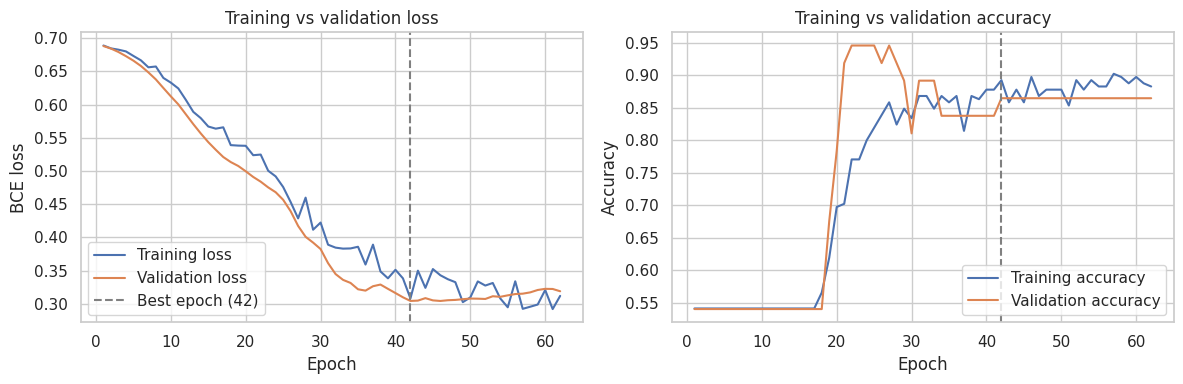

Final train loss: 0.3119 | final val loss: 0.3189
Lowest val loss : 0.3043 at epoch 42


In [ ]:
# Plot training and validation loss (and accuracy) from `history`
epochs = range(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, history["train_loss"], label="Training loss")
axes[0].plot(epochs, history["val_loss"], label="Validation loss")
axes[0].axvline(best_epoch, color="grey", linestyle="--", label=f"Best epoch ({best_epoch})")
axes[0].set_title("Training vs validation loss")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("BCE loss"); axes[0].legend()

axes[1].plot(epochs, history["train_acc"], label="Training accuracy")
axes[1].plot(epochs, history["val_acc"], label="Validation accuracy")
axes[1].axvline(best_epoch, color="grey", linestyle="--")
axes[1].set_title("Training vs validation accuracy")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy"); axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Final train loss: {history['train_loss'][-1]:.4f} | final val loss: {history['val_loss'][-1]:.4f}")
print(f"Lowest val loss : {min(history['val_loss']):.4f} at epoch {best_epoch}")

**Comment — overfitting:** both losses fall steadily together from ≈ 0.69 to ≈ 0.31 during the first ~40 epochs, and validation loss stays at or slightly below training loss throughout (training loss is measured with dropout active, which inflates it). The lowest validation loss (0.304) was reached at **epoch 42**; after that validation loss stopped improving and started to rise slightly, so **early stopping** ended training at epoch 62 and the epoch-42 weights were restored. There is **no significant overfitting**: the gap between the curves is small, and early stopping, dropout and weight decay prevent the model from memorising the training data. Note the validation set is small (37 samples), so its curve is somewhat noisy.

## Cell 17 — Evaluate Neural Network

Make predictions on the test set and calculate accuracy, precision, recall, and F1-score.

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import torch

# Put model in evaluation mode
model.eval()

y_true = []
y_prob = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:

        # Model predictions
        outputs = model(X_batch)

        # Model outputs a single logit -> sigmoid gives probability of disease
        probabilities = torch.sigmoid(outputs).squeeze(1)

        y_prob.extend(probabilities.cpu().numpy())
        y_true.extend(y_batch.squeeze(1).cpu().numpy().astype(int))

# Convert probabilities to binary predictions
threshold = 0.5
y_pred_nn = [1 if p >= threshold else 0 for p in y_prob]

# Calculate metrics
accuracy = accuracy_score(y_true, y_pred_nn)
precision = precision_score(y_true, y_pred_nn, zero_division=0)
recall = recall_score(y_true, y_pred_nn, zero_division=0)
f1 = f1_score(y_true, y_pred_nn, zero_division=0)

nn_metrics = {"Accuracy": accuracy, "Precision": precision, "Recall": recall, "F1-Score": f1}

# Display results
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

from sklearn.metrics import confusion_matrix
print("\nConfusion matrix [rows = actual 0/1, cols = predicted 0/1]:")
print(confusion_matrix(y_true, y_pred_nn))

Accuracy : 0.8852
Precision: 0.8182
Recall   : 0.9643
F1-score : 0.8852

Confusion matrix [rows = actual 0/1, cols = predicted 0/1]:
[[27  6]
 [ 1 27]]


## Cell 18 — Build AdaBoost Classifier

Build a second model using `AdaBoostClassifier`:
- Create the model
- Train it
- Make predictions
- Calculate accuracy, precision, recall, and F1-score

In [ ]:
# Create, train, and evaluate an AdaBoostClassifier
# Uses the SAME preprocessed train/test data as the neural network (full training set).
ada_model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1),  # decision stumps (classic AdaBoost)
    n_estimators=100,
    learning_rate=0.5,
    random_state=42
)

# Fit on training data
ada_model.fit(X_train_np, y_train_s)

# Predict on test data
y_pred_ada = ada_model.predict(X_test_np)

# Calculate and display accuracy, precision, recall, and F1-score
ada_metrics = {
    "Accuracy": accuracy_score(y_test_s, y_pred_ada),
    "Precision": precision_score(y_test_s, y_pred_ada, zero_division=0),
    "Recall": recall_score(y_test_s, y_pred_ada, zero_division=0),
    "F1-Score": f1_score(y_test_s, y_pred_ada, zero_division=0),
}
for k, v in ada_metrics.items():
    print(f"{k:9s}: {v:.4f}")

print("\nTraining accuracy:", round(accuracy_score(y_train_s, ada_model.predict(X_train_np)), 4))
print("\nConfusion matrix [rows = actual 0/1, cols = predicted 0/1]:")
print(confusion_matrix(y_test_s, y_pred_ada))

# Top features used by AdaBoost
imp = pd.Series(ada_model.feature_importances_, index=feature_names).sort_values(ascending=False)
print("\nTop 8 feature importances:")
print(imp.head(8).round(3))

Accuracy : 0.9016
Precision: 0.8667
Recall   : 0.9286
F1-Score : 0.8966

Training accuracy: 0.876

Confusion matrix [rows = actual 0/1, cols = predicted 0/1]:
[[29  4]
 [ 2 26]]

Top 8 feature importances:
num__thalach     0.152
num__chol        0.132
num__ca          0.118
num__trestbps    0.098
num__oldpeak     0.097
num__age         0.080
cat__cp_4.0      0.073
cat__sex_1.0     0.071
dtype: float64


## Cell 19 — Compare Both Models

| Model          | Accuracy | Precision | Recall | F1-Score |
|----------------|---------:|----------:|-------:|---------:|
| Neural Network | 0.8852 | 0.8182 | 0.9643 | 0.8852 |
| AdaBoost       | 0.9016 | 0.8667 | 0.9286 | 0.8966 |

**Discussion:**

- **Differences in metrics:** AdaBoost is slightly better on accuracy (+1.6 pts), precision (+4.9 pts) and F1 (+1.1 pts). The neural network has the **higher recall** (0.964 vs 0.929): it missed only 1 of 28 patients with disease, but produced more false alarms (6 false positives vs 4). In other words, the NN is more "cautious" (predicts disease more often), AdaBoost is more balanced. On a 61-patient test set, one patient = 1.6 percentage points, so the gap is only 1 test patient in accuracy and the two models perform **very similarly**.
- **Possible reasons:** AdaBoost with decision stumps works very well on small **tabular** data — it picks up simple thresholds (e.g. `thalach`, `ca`, `oldpeak`, `cp = 4`) and is less sensitive to the small sample size. The neural network has 1,409 parameters but only 205 training samples (37 were held out for validation, while AdaBoost used all 242), so it has less data and more variance. The NN's 0.5 threshold also favours recall here; a different threshold would trade recall for precision.
- **Overfitting of the NN:** no strong signs — training and validation losses stay close (Cell 15), training accuracy at the best epoch (~0.88) is similar to test accuracy (0.885), and early stopping restored the best-validation weights. AdaBoost likewise shows a training accuracy (0.876) close to its test accuracy.
- **Effect of preprocessing:** **standard scaling** was essential for the neural network (gradient-based training is sensitive to feature scale, e.g. `chol` ~250 vs `oldpeak` ~1); tree-based AdaBoost is scale-invariant. **One-hot encoding** stopped the NN from treating codes like `cp` = 1…4 or `thal` = 3/6/7 as ordered quantities. **Imputation** kept all 303 patients, and fitting the pipeline on the training set only ensured the test scores are honest (no leakage).

                Accuracy  Precision  Recall  F1-Score
Neural Network    0.8852     0.8182  0.9643    0.8852
AdaBoost          0.9016     0.8667  0.9286    0.8966


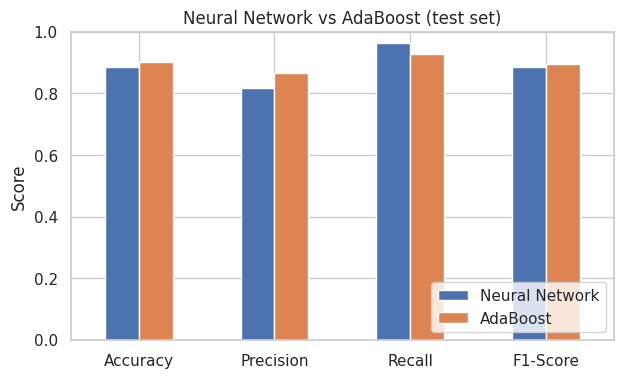

In [ ]:
# Comparison table
comparison = pd.DataFrame([nn_metrics, ada_metrics], index=["Neural Network", "AdaBoost"]).round(4)
print(comparison)

comparison.T.plot(kind="bar", figsize=(7, 4), ylim=(0, 1), rot=0)
plt.title("Neural Network vs AdaBoost (test set)")
plt.ylabel("Score")
plt.legend(loc="lower right")
plt.show()

## Cell 20 — Final Interpretation

1. **Balance:** the dataset is approximately **balanced** — 164 (54.1%) no disease vs 139 (45.9%) disease (ratio 0.85), so no resampling was needed; a stratified split preserved this ratio.
2. **Preprocessing:** the target was converted from 0–4 to binary; `'?'` was read as NaN; the 6 missing values in `ca` (median) and `thal` (mode) were imputed; 7 categorical features were one-hot encoded; 6 numerical features were standardised; data was split 80/20 (stratified) and the `ColumnTransformer` was fitted on the training set only to avoid leakage. 15% of the training data was held out for validation.
3. **Architecture:** a feed-forward network 22 → 32 → 16 → 8 → 1 (ReLU hidden layers, sigmoid output, dropout 0.3, 1,409 trainable parameters), trained with Binary Cross-Entropy (`BCEWithLogitsLoss`), Adam (lr = 0.001, weight decay = 1e-4), batch size 32 and early stopping (patience 20).
4. **Neural network results:** accuracy **0.885**, precision **0.818**, recall **0.964**, F1 **0.885** — it caught 27 of 28 disease cases, which is valuable in a medical screening context where missing a patient is costly.
5. **AdaBoost results:** accuracy **0.902**, precision **0.867**, recall **0.929**, F1 **0.897** using 100 decision stumps; the most important features were `thalach`, `chol`, `ca`, `trestbps` and `oldpeak`.
6. **Comparison:** AdaBoost was marginally better overall (accuracy, precision, F1), while the neural network had the best recall. The differences correspond to only 1–2 test patients, so both models are comparably strong; on small tabular datasets, boosted trees are typically as good as or better than neural networks with far less tuning.
7. **Improvements:** use **stratified k-fold cross-validation** (a single 61-sample test set is noisy); tune hyperparameters (layer sizes, dropout, learning rate, `n_estimators`, `learning_rate`) with grid/random search; **tune the decision threshold** or use ROC-AUC to choose the precision/recall trade-off; try other models (Random Forest, Gradient Boosting/XGBoost, Logistic Regression) or an ensemble of the NN and AdaBoost; add batch normalization; and train on the combined UCI data (Cleveland + Hungary + Switzerland + VA Long Beach) for more samples.